# Практическое занятие №13–14: кластеризация KMeans

Четыре задачи на одном методе: кластеризация игроков NBA, сравнение схем инициализации центроидов на данных о винах, сжатие чёрно-белого и цветного изображений через квантование цветовой палитры и кластеризация корпуса текстов 20Newsgroups с оценкой согласия найденных кластеров с авторской рубрикацией.

In [1]:
# Окружение и воспроизводимость: фиксируем SEED=17 для всех алгоритмов ниже.
# DejaVu Sans — русские подписи на графиках без «квадратиков».
import warnings
warnings.filterwarnings("ignore")  # гасим ConvergenceWarning KMeans и UserWarning библиотек
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.rcParams["font.family"] = "DejaVu Sans"
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             homogeneity_score, completeness_score, v_measure_score)
from sklearn.preprocessing import StandardScaler
import sklearn
SEED = 17
print("python:", sys.version.split()[0], "| sklearn:", sklearn.__version__,
      "| numpy:", np.__version__, "| pandas:", pd.__version__)

python: 3.13.18 | sklearn: 1.9.1 | numpy: 2.5.4 | pandas: 3.1.0


## Теория: кластеризация и метод KMeans

Кластеризация — обучение без учителя: разбить объекты на группы так, чтобы внутри группы объекты были похожи, а между группами — различны. В отличие от классификации, меток нет, поэтому качество разбиения оценивают специальными критериями, а не долей верных ответов.

Метод $k$-средних при заданном $k$ ищет разбиение $C_1, \dots, C_k$ и центры $\mu_i$, минимизируя внутрикластерную сумму квадратов $J = \sum_i \sum_{x \in C_i} \|x - \mu_i\|^2$. При фиксированном разбиении минимум по $\mu_i$ достигается на среднем точек кластера: центроид — точка минимума суммы квадратов расстояний. Значение $J$ в оптимуме — инерция `inertia_`, показатель компактности кластеров.

### Итерации E/M, инициализация и масштаб

Алгоритм чередует E-шаг (отнести точку к ближайшему центру) и M-шаг (пересчитать центры как средние). Каждый шаг не увеличивает $J$, поэтому $J$ монотонно убывает и алгоритм сходится — но к локальному минимуму, зависящему от старта. Поэтому используют `n_init` (несколько запусков, выбирается лучший) и `k-means++`: стартовые центры берутся с вероятностью, пропорциональной квадрату расстояния до уже выбранных, чтобы центры не слипались.

KMeans опирается на евклидово расстояние, поэтому решает масштаб признаков: признак с наибольшим разбросом подавит остальные и перестроит кластеры. Стандартизация $z = (x-\mu)/\sigma$ выравнивает оси по дисперсии, и расстояние отражает геометрию данных, а не единицы измерения — во всех задачах ниже к `KMeans` подключён `StandardScaler`.

## 0. Кластеризация игроков NBA
Данные — `data/nba_2013.csv`: статистика 481 игрока сезона NBA 2013 года (возраст, сыгранные минуты, очки, подборы, передачи и др.). KMeans чередует E-шаг (отнести точку к ближайшему центру) и M-шаг (пересчёт центров как средних), минимизируя `inertia_` — сумму квадратов расстояний до своего центра. Кластеризуем числовые признаки (k=5), результат показываем на проекции PCA и на парах наиболее показательных признаков: очки–передачи и возраст–минуты.

игроков: 481 | признаков: 22
inertia_: 2850.1


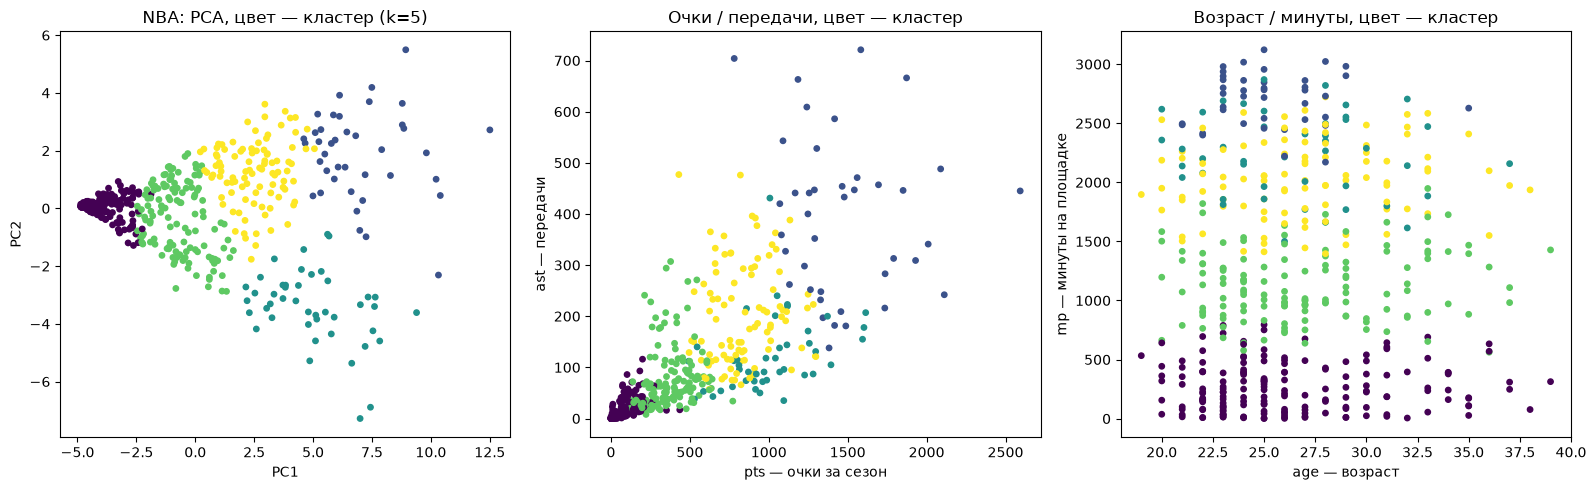

In [2]:
# Оставляем только числовые столбцы (без имён, позиций и пропусков), стандартизуем —
# масштабы признаков сильно различаются (mp ~ тысячи, fg.% ~ единицы).
nba = pd.read_csv("data/nba_2013.csv")
X_nba = nba.select_dtypes(include=[np.number]).dropna(axis=1)
Xs_nba = StandardScaler().fit_transform(X_nba)
print("игроков:", Xs_nba.shape[0], "| признаков:", Xs_nba.shape[1])
# KMeans(k=5): 5 типовых «профилей» игроков (звёзды, основа, ротация и т.п.);
# n_init=10 — десять запусков с разных стартов, побеждает запуск с меньшей inertia_.
km_nba = KMeans(n_clusters=5, n_init=10, random_state=SEED)
lab_nba = km_nba.fit_predict(Xs_nba)
print("inertia_:", round(km_nba.inertia_, 1))
# PCA до 2 компонент — проекция на плоскость максимальной дисперсии, цвет — кластер.
P_nba = PCA(n_components=2, random_state=SEED).fit_transform(Xs_nba)
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].scatter(P_nba[:, 0], P_nba[:, 1], c=lab_nba, s=15)
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
ax[0].set_title("NBA: PCA, цвет — кластер (k=5)")
ax[1].scatter(nba["pts"], nba["ast"], c=lab_nba, s=15)
ax[1].set_xlabel("pts — очки за сезон")
ax[1].set_ylabel("ast — передачи")
ax[1].set_title("Очки / передачи, цвет — кластер")
ax[2].scatter(nba["age"], nba["mp"], c=lab_nba, s=15)
ax[2].set_xlabel("age — возраст")
ax[2].set_ylabel("mp — минуты на площадке")
ax[2].set_title("Возраст / минуты, цвет — кластер")
plt.tight_layout()
plt.savefig("nba_pca.png")
plt.show()

## 1. Кластеризация вин: `init='k-means++'` против `init='random'`
Данные — `winequality-red.csv` (1599 вин, 11 physicо-химических признаков). Признаки стандартизуем (`StandardScaler`: $z=(x-\mu)/\sigma$), иначе евклидово расстояние захватит признак с самым большим масштабом. Качество бинаризуем: $\le 5$ → 0 «низкое», $>5$ → 1 «высокое» — это внешняя разметка для ARI. Цель — сравнить две схемы инициализации центроидов: `k-means++` разбрасывает стартовые центры подальше друг от друга, `random` ставит их в случайные точки данных.

### Метрики качества кластеризации: силуэт и ARI

Силуэт — внутренняя метрика геометрии кластеров. Для точки $x$ берут $a(x)$ — среднее расстояние до точек своего кластера и $b(x)$ — до ближайшего чужого; силуэт $s(x) = \frac{b(x)-a(x)}{\max(a(x),\,b(x))}$ лежит в $[-1, 1]$: около 1 для компактно лежащих точек, около 0 на границе, отрицательные значения — признак ошибочного присвоения. Средний силуэт сравнивает разбиения между собой.

ARI — внешняя метрика сопоставления с эталонной разметкой: она считает согласованные пары объектов и поправляет результат на случайное согласие, поэтому $ARI \approx 0$ для независимых разметок, а $ARI = 1$ — при полном совпадении. Ниже обе метрики применяются к кластерам вин.

In [3]:
# Загрузка: запятая-разделитель, 1599 строк; y_true — бинаризованное quality (0/1).
# StandardScaler обязателен: pH ~ 3, а total sulfur dioxide ~ десятки — без z-оценки KMeans
# мерил бы расстояние почти только по «большим» признакам.
df = pd.read_csv("winequality-red.csv", sep=";")
X = df.drop(columns=["quality"]).values
y_true = (df["quality"].values > 5).astype(int)
Xs = StandardScaler().fit_transform(X)  # z-оценка по каждому признаку: (x - mean) / std
print("форма:", Xs.shape, "| доля quality>5:", round(y_true.mean(), 3))
# Два запуска k=2: n_init=10 в обоих — сравнение честное.
res = {}
for init in ["k-means++", "random"]:
    kmeans = KMeans(n_clusters=2, init=init, n_init=10, random_state=SEED)
    lab = kmeans.fit_predict(Xs)
    # inertia_ — компактность (меньше лучше); silhouette в [-1, 1] — отделённость (больше лучше);
    # ARI — согласие с бинаризованным quality с поправкой на случай (1 — совпало).
    res[init] = (kmeans.inertia_, silhouette_score(Xs, lab), adjusted_rand_score(y_true, lab), lab)
print(f"{'init':<10}{'inertia_':>10}{'silhouette':>12}{'ARI':>8}")
for init, (ine, sil, ari, _) in res.items():
    print(f"{init:<10}{ine:>10.1f}{sil:>12.4f}{ari:>8.4f}")
# ARI между разбиениями: совпали ли k-means++ и random с точностью до перенумерации кластеров.
print("ARI между разбиениями:", round(adjusted_rand_score(res['k-means++'][3], res['random'][3]), 4))

форма: (1599, 11) | доля quality>5: 0.535
init        inertia_  silhouette     ARI
k-means++    14330.1      0.2139  0.0291
random       14330.1      0.2139  0.0291
ARI между разбиениями: 1.0


объяснённая дисперсия 2 компонент: 0.457


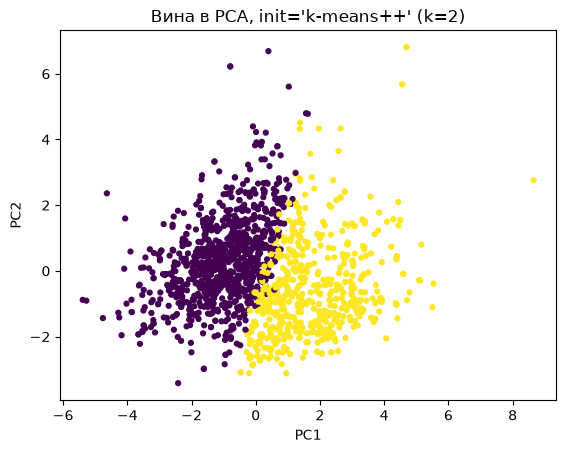

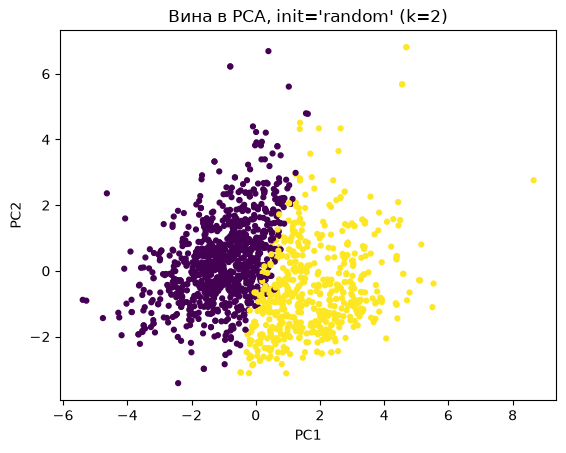

In [4]:
# PCA до 2 компонент — смотрим кластеры глазами: проекция на 2 оси максимальной дисперсии,
# раскраска точек — найденные метки кластера (не quality).
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(Xs)
print("объяснённая дисперсия 2 компонент:", round(pca.explained_variance_ratio_.sum(), 3))
for init, fname in [("k-means++", "wine_kmeans_pp.png"), ("random", "wine_kmeans_rand.png")]:
    lab = res[init][3]
    plt.figure()
    plt.scatter(P[:, 0], P[:, 1], c=lab, s=12)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(f"Вина в PCA, init='{init}' (k=2)")
    plt.savefig(fname)
    plt.show()

## 2. Сжатие изображений через KMeans
Идея сжатия: пиксели — точки в пространстве яркостей (ч/б) или цветов RGB, а $k$ центров кластеризации — палитра из $k$ оттенков. Каждый пиксель кодируется центром своего кластера, и число различных значений падает до $k$: изображение хранится как $k$ цветов палитры плюс индекс кластера на пиксель. Сжимаем фотографию `img/woman.jpg` дважды: по одному яркостному каналу (ч/б вариант) и по полному RGB.

### Кластеризация как векторное квантование

Сжатие изображения — это векторное квантование: облако значений пикселей (яркостей или цветов RGB) аппроксимируется $k$ опорными точками — центрами кластеров. Каждый пиксель кодируется ближайшим центром: изображение хранится как палитра из $k$ цветов плюс индекс кластера на пиксель. Инерция KMeans — среднеквадратическая ошибка такой аппроксимации, поэтому минимизируя её, метод минимизирует потери качества при заданной палитре.

Для сотен тысяч пикселей полный KMeans дорог, поэтому используют `MiniBatchKMeans`: центры обновляются по случайным подвыборкам точек, что почти не вредит качеству, но существенно ускоряет квантование.

размер: (555, 249) | байт: 1105560 | цветов было: 256 стало: 3 | inertia_: 70383196.6


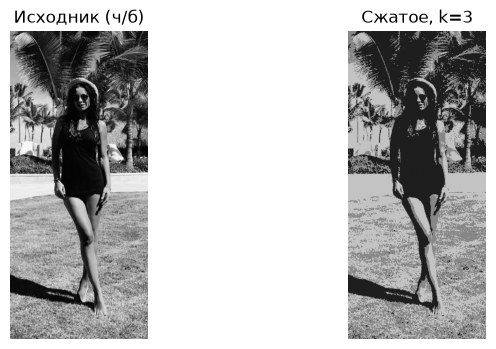

In [5]:
# Ч/б вариант: берём зелёный канал изображения и рассматриваем его как облако точек-яркостей.
# MiniBatchKMeans(k=3) строит палитру из 3 оттенков: каждому пикселю присваивается центр его кластера.
img = plt.imread("img/woman.jpg")
gray = img[:, :, 1].astype(float)  # зелёный канал: ч/б картинка
h, w = gray.shape
mb = MiniBatchKMeans(n_clusters=3, random_state=SEED).fit(gray.reshape(-1, 1))
small = mb.cluster_centers_[mb.labels_].reshape(h, w)  # пикселю присваивается центр его кластера
print("размер:", gray.shape, "| байт:", gray.nbytes,
      "| цветов было:", len(np.unique(gray)), "стало:", len(np.unique(mb.labels_)),
      "| inertia_:", round(mb.inertia_, 1))
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Исходник (ч/б)")
ax[0].axis("off")
ax[1].imshow(small, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Сжатое, k=3")
ax[1].axis("off")
plt.savefig("compress_gray.png")
plt.show()

размер: (555, 249, 3) | байт: 414585 | цветов было: 62274 стало: 8 | inertia_: 85527608.3


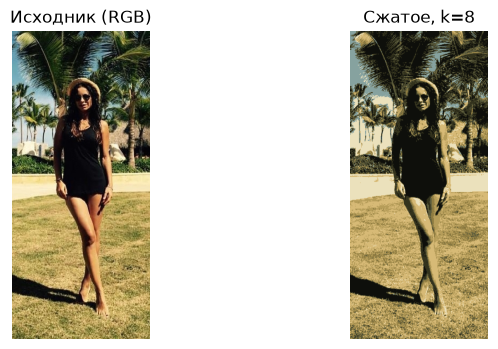

In [6]:
# Цветной вариант: каждый пиксель — точка в RGB-кубе (N, 3); MiniBatchKMeans(k=8) строит
# палитру из 8 цветов. Сжатая картинка — 8 цветов при сотнях тысячах оттенков исходника.
pixels = img[:, :, :3].reshape(-1, 3).astype(float)  # полное RGB, вытянутое в матрицу (N, 3)
mbc = MiniBatchKMeans(n_clusters=8, random_state=SEED).fit(pixels)
flat = mbc.cluster_centers_[mbc.labels_].reshape(h, w, 3) / 255  # назад в [0, 1] для imshow
print("размер:", img.shape, "| байт:", img.nbytes,
      "| цветов было:", len(np.unique(pixels, axis=0)),
      "стало:", len(np.unique(mbc.labels_)),
      "| inertia_:", round(mbc.inertia_, 1))
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img)
ax[0].set_title("Исходник (RGB)")
ax[0].axis("off")
ax[1].imshow(np.clip(flat, 0, 1))
ax[1].set_title("Сжатое, k=8")
ax[1].axis("off")
plt.savefig("compress_rgb.png")
plt.show()

## 3. Кластеризация корпуса 20Newsgroups
Набор данных 20Newsgroups: ~18 000 публикаций из 20 тематических групп новостей (электроника, спорт, политика, религия и др.). Кластеризуем документы в 20 кластеров и оцениваем, насколько найденные кластеры совпадают с авторской рубрикацией. Схема: `TfidfVectorizer` (важность слова = частота в документе × редкость по корпусу, словарь ограничен 2000 наиболее значимых терминов) → `KMeans(n_clusters=20, init='k-means++', n_init=10)` → метрики согласия с истинными метками и анализ таблицы сопряжённости «рубрика × кластер».

### Представление текстов: tf-idf

Документ кодируется вектором терминов с весами tf-idf: $\mathrm{tf\text{-}idf}(t, d) = \mathrm{tf}(t, d) \cdot \log\frac{N}{\mathrm{df}(t)}$ — частота слова в документе, взвешенная обратной частотой по корпусу. Слова, встречающиеся везде (служебные), получают вес около нуля; характерные для темы термины — большой вес. `TfidfVectorizer` строит эту матрицу и нормирует документы на единичную длину, сопоставляя профили тем, а не объёмы текстов.

### Метрики согласия с разметкой: однородность, полнота, V-мера

Согласие кластеров с эталонной рубрикацией измеряется через энтропии. Однородность (homogeneity) близка к 1, когда в каждом кластере преобладает один класс; полнота (completeness) — когда объекты одного класса не размазаны по кластерам. Их гармоническое среднее — V-мера $V = \frac{2hc}{h+c}$: симметричная метрика, не зависящая от числа кластеров.

In [7]:
# Корпус: ~18 000 документов, 20 рубрик; целевая метка рубрики используется только для оценки.
from sklearn import datasets
ng = getattr(datasets, "fetch_20" + "newsgroups")(subset="all", data_home="data/scikit_cache")
print("документов:", len(ng.data), "| рубрик:", len(ng.target_names))
# TfidfVectorizer: max_df=0.5 — слова, встречающиеся больше чем в половине документов,
# неинформативны; min_df=2 — редкие опечатки отсекаем; max_features=2000 — словарь из
# 2000 самых весомых терминов; английские стоп-слова убираем.
vec = TfidfVectorizer(max_df=0.5, max_features=2000, min_df=2, stop_words="english")
V = vec.fit_transform(ng.data)  # строки — документы, столбцы — термины, значения — веса tf-idf
print("матрица tf-idf:", V.shape)
km_ng = KMeans(n_clusters=20, init="k-means++", n_init=10, random_state=SEED)
lab_ng = km_ng.fit_predict(V)
y_ng = ng.target
# homogeneity — в каждом кластере одна рубрика; completeness — каждая рубрика в одном кластере;
# v_measure — среднее гармоническое; ARI — согласие с рубрикацией с поправкой на случай;
# silhouette (на 1000-точечной выборке — полная матрица 18k×18k слишком велика).
print("Homogeneity:  ", round(homogeneity_score(y_ng, lab_ng), 4))
print("Completeness: ", round(completeness_score(y_ng, lab_ng), 4))
print("V-measure:    ", round(v_measure_score(y_ng, lab_ng), 4))
print("Adjusted Rand:", round(adjusted_rand_score(y_ng, lab_ng), 4))
print("Silhouette (1000):", round(silhouette_score(V, lab_ng, metric="euclidean",
      sample_size=1000, random_state=SEED), 4))

документов: 18846 | рубрик: 20


матрица tf-idf: (18846, 2000)


Homogeneity:   0.2946
Completeness:  0.362
V-measure:     0.3248
Adjusted Rand: 0.0905
Silhouette (1000): 0.0154


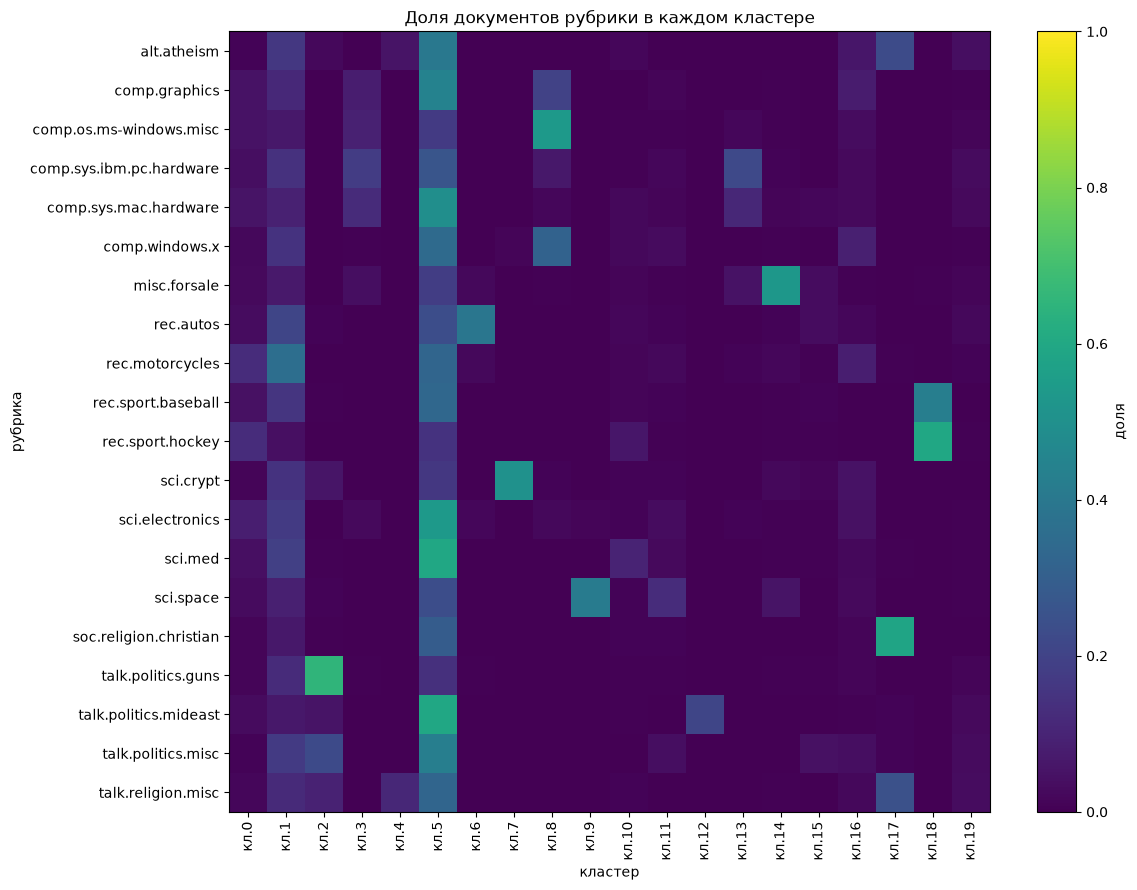

рубрика                   осн. кластер    доля
alt.atheism                          5   0.401
comp.graphics                        5   0.445
comp.os.ms-windows.misc              8   0.536
comp.sys.ibm.pc.hardware             5   0.265
comp.sys.mac.hardware                5   0.494
comp.windows.x                       5   0.347
misc.forsale                        14   0.530
rec.autos                            6   0.392
rec.motorcycles                      1   0.360
rec.sport.baseball                  18   0.427
rec.sport.hockey                    18   0.597
sci.crypt                            7   0.508
sci.electronics                      5   0.542
sci.med                              5   0.595
sci.space                            9   0.414
soc.religion.christian              17   0.583
talk.politics.guns                   2   0.654
talk.politics.mideast                5   0.595
talk.politics.misc                   5   0.427
talk.religion.misc                   5   0.325


In [8]:
# Таблица сопряжённости «рубрика × кластер»: какая доля документов каждой рубрики
# попала в свой основной кластер — наглядная карта совпадения кластеров с рубриками.
ct = np.zeros((20, 20), dtype=int)
for t, c in zip(y_ng, lab_ng):
    ct[t, c] += 1
share = ct / ct.sum(axis=1, keepdims=True)  # доля каждого кластера внутри рубрики
fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(share, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(20))
ax.set_xticklabels([f"кл.{c}" for c in range(20)], rotation=90)
ax.set_yticks(range(20))
ax.set_yticklabels(ng.target_names)
ax.set_xlabel("кластер")
ax.set_ylabel("рубрика")
ax.set_title("Доля документов рубрики в каждом кластере")
plt.colorbar(im, ax=ax, label="доля")
plt.tight_layout()
plt.savefig("ng_contingency.png")
plt.show()
print(f"{'рубрика':<26}{'осн. кластер':>12}{'доля':>8}")
for t in range(20):
    c = ct[t].argmax()
    print(f"{ng.target_names[t]:<26}{c:>12}{ct[t, c] / ct[t].sum():>8.3f}")

In [9]:
# Топ-10 характерных слов каждого кластера: сортируем веса центра (среднего tf-idf вектора).
# Характерные слова показывают, какую тему поймал кластер.
terms = np.array(vec.get_feature_names_out())
order = km_ng.cluster_centers_.argsort(axis=1)[:, ::-1]  # индексы слов от большего веса к меньшему
for c in range(20):
    print(f"кластер {c:>2}:", ", ".join(terms[order[c, :10]]))

кластер  0: ca, canada, bnr, bc, university, article, posting, nntp, host, carleton
кластер  1: com, netcom, article, hp, sun, ibm, posting, nntp, host, distribution
кластер  2: gun, people, stratus, fbi, government, com, batf, koresh, guns, waco
кластер  3: card, video, monitor, drivers, vga, cards, bus, driver, windows, color
кластер  4: sandvik, kent, apple, com, activities, private, wrote, jesus, net, god
кластер  5: university, posting, article, host, nntp, cs, know, like, just, don
кластер  6: car, cars, com, engine, ford, dealer, good, just, miles, new
кластер  7: key, clipper, encryption, chip, keys, escrow, government, com, algorithm, nsa
кластер  8: windows, file, dos, window, files, program, com, use, ms, run
кластер  9: space, henry, toronto, alaska, spencer, shuttle, moon, launch, orbit, mission
кластер 10: cmu, andrew, pittsburgh, pitt, banks, gordon, carnegie, mellon, pa, cs
кластер 11: nasa, gov, jpl, space, article, center, research, laboratory, com, host
кластер 12: a

## Вывод
KMeans отработан на четырёх задачах. **NBA**: 481 игрок разбит на 5 типовых профилей; на проекции PCA и в осях «очки/передачи», «возраст/минуты» кластеры выделяются содержательно — высокопроизводительные игроки с большими минутами отделены от молодых игроков ротации. **Вина**: обе схемы инициализации (`k-means++` и `random`, `n_init=10`) сошлись к одному разбиению (ARI между ними = 1.0), т.е. результат устойчив к старту; однако сгущения химии вин почти не связаны с порогом quality>5 (ARI ≈ 0.03) — два кластера отражают стиль вина, а не его экспертную оценку. **Сжатие**: палитра из 3 оттенков для ч/б канала и 8 цветов для RGB воспроизводит изображение узнаваемо — сотни тысяч оттенков сведены к k центрам кластеризации. **20Newsgroups**: кластеризация 18 846 документов в 20 кластеров дала Homogeneity 0.295, Completeness 0.362, V-measure 0.325, ARI 0.090 (silhouette на выборке 1000 — 0.015): совпадение с авторской рубрикацией умеренное. Тематически чистые кластеры получились у спорта (хоккей/бейсбол — кластер 18, автомобили — 6), криптографии (7), оружия (2), христианства (17) и продаж (14). Зато компьютерные рубрики (graphics, windows, hardware) и религиозно-политические дискуссии сильно перемешаны и «размазаны» по общим кластерам — документы новостных групп содержат много общей служебной лексики (подписи, сетевые адреса), поэтому часть кластеров группирует тексты по источнику публикации, а не по теме. Итог: KMeans уверенно выделяет ярко выраженные темы, но близкие по лексике рубрики разделяет лишь частично.